#Tests for .in files

##MSD visualizer

12 organelles, 2001 frames, lag up to 2000.0 tau
alpha = 1.002   (1 = normal diffusion, <1 = caged/subdiffusive)
D_sim = 0.03523 r_c^2/tau
Calibrate: TAU_S = D_sim * RC_UM**2 / D_measured_um2_per_s, then rerun
wrote c:\Users\andre\iCloudDrive\Uni\Semestre 7\Avanzado\Simulation_BioTissue_FBDHS\DPD tissue\graphs\m1_msd.png and c:\Users\andre\iCloudDrive\Uni\Semestre 7\Avanzado\Simulation_BioTissue_FBDHS\DPD tissue\code\run_files\mito_com.npz


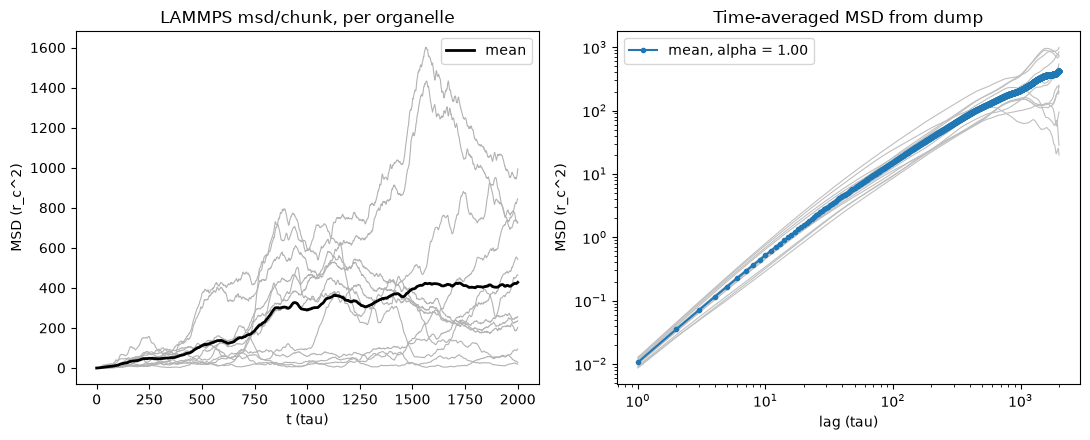

In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from utilities import read_msd_dat, read_dump_com, msd_time_averaged, fit_power_law

# The notebook runs from DPD tissue/code
CODE_DIR = Path.cwd()
RUN_DIR = CODE_DIR / "run_files"
GRAPHS_DIR = CODE_DIR.parent / "graphs"

DT = 0.01        # must match `timestep` in the input script

# Settings
run = RUN_DIR    # run folder with msd_mito.dat and dump.m1
RC_UM = 0.25     # bead size r_c in micrometres
FIT_FROM = 0.1   # fit lags above this fraction of the longest lag
TAU_S = None     # DPD time unit in seconds (after calibration)

# 1. MSD written by LAMMPS (single time origin, one curve per mitochondrion)
steps, msd_lmp = read_msd_dat(run / "msd_mito.dat")
t_lmp = steps * DT

# 2. MSD from the dump, averaged over time origins (smoother)
dsteps, com = read_dump_com(run / "dump.m1")
lags, msd, per_mito = msd_time_averaged(com)
t = lags * (dsteps[1] - dsteps[0]) * DT

# 3. Fits on long lags only (short lags are ballistic, alpha ~ 2):
#    alpha from the log-log slope, D from MSD = 6 D t (3D)
late = t >= FIT_FROM * t[-1]
alpha, _ = fit_power_law(t[late], msd[late])
D_sim = np.polyfit(t[late], msd[late], 1)[0] / 6
print(f"{com.shape[1]} organelles, {len(dsteps)} frames, lag up to {t[-1]:.1f} tau")
print(f"alpha = {alpha:.3f}   (1 = normal diffusion, <1 = caged/subdiffusive)")
print(f"D_sim = {D_sim:.4g} r_c^2/tau")
if TAU_S:
    print(f"D     = {D_sim * RC_UM**2 / TAU_S:.4g} um^2/s  (r_c = {RC_UM} um, tau = {TAU_S} s)")
else:
    print("Calibrate: TAU_S = D_sim * RC_UM**2 / D_measured_um2_per_s, then rerun")

# 4. Plots
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].plot(t_lmp, msd_lmp, color="0.7", lw=0.8)
ax[0].plot(t_lmp, msd_lmp.mean(axis=1), "k", lw=2, label="mean")
ax[0].set(xlabel="t (tau)", ylabel="MSD (r_c^2)", title="LAMMPS msd/chunk, per organelle")
ax[0].legend()
ax[1].loglog(t, per_mito, color="0.75", lw=0.8)
ax[1].loglog(t, msd, "o-", ms=3, label=f"mean, alpha = {alpha:.2f}")
ax[1].set(xlabel="lag (tau)", ylabel="MSD (r_c^2)", title="Time-averaged MSD from dump")
ax[1].legend()
fig.tight_layout()
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(GRAPHS_DIR / "m1_msd.png", dpi=150)

# 5. Save COM trajectories for the optics model
np.savez(run / "mito_com.npz", time_tau=dsteps * DT, com_rc=com, rc_um=RC_UM,
         tau_s=TAU_S if TAU_S else np.nan)
print(f"wrote {GRAPHS_DIR / 'm1_msd.png'} and {run / 'mito_com.npz'}")

In [3]:
"""Write a LAMMPS data file and input script for M1: rigid mitochondria in a DPD cytoplasm.
Units: DPD reduced units (r_c = 1). With r_c = 0.25 um, a mitochondrion of
radius 1 and length 8 is 0.5 um wide and 2 um long."""
import numpy as np
from geometry import capsule, dist_to_segment
from pathlib import Path

RUN_DIR = Path("run_files")
RUN_DIR.mkdir(exist_ok=True)

rng = np.random.default_rng(1)
BOX = np.array([40.0, 40.0, 8.0])   # x y z in r_c (10 x 10 x 2 um), periodic
RHO = 3.0                           # DPD bead density
N_MITO = 12                         # number of mitochondria
R, L = 1.0, 8.0                     # capsule radius and total length

# 1. Place mitochondria lying in the xy plane, rejecting overlaps
mitos = []                                         # (center, axis)
while len(mitos) < N_MITO:
    c = np.array([rng.uniform(0, BOX[0]), rng.uniform(0, BOX[1]), BOX[2] / 2])
    th = rng.uniform(0, np.pi)
    a = np.array([np.cos(th), np.sin(th), 0.0])
    beads = capsule(c, a, R, L)
    if all(dist_to_segment(beads, c2, a2, L / 2 - R, BOX).min() > R + 0.5 for c2, a2 in mitos):
        mitos.append((c, a))

# 2. Fill the rest with cytoplasm beads at density RHO
cyto = rng.uniform(0, 1, (int(RHO * BOX.prod()), 3)) * BOX
for c, a in mitos:
    cyto = cyto[dist_to_segment(cyto, c, a, L / 2 - R, BOX) > R]

# 3. Collect atoms: (mol, type, x, image); cytoplasm = type 1 mol 0, mitochondria = type 2
atoms = [(0, 1, x, (0, 0, 0)) for x in cyto]
for m, (c, a) in enumerate(mitos, start=1):
    for x in capsule(c, a, R, L):
        img = np.floor(x / BOX).astype(int)        # image flags keep each body whole
        atoms.append((m, 2, x - img * BOX, img))

# 4. Data file (atom_style bond: id mol type x y z ix iy iz)
with open(RUN_DIR / "m1_mito.data", "w") as f:
    f.write(f"M1 mitochondria in DPD cytoplasm\n\n{len(atoms)} atoms\n2 atom types\n\n")
    f.write(f"0 {BOX[0]} xlo xhi\n0 {BOX[1]} ylo yhi\n0 {BOX[2]} zlo zhi\n\n")
    f.write("Masses\n\n1 1.0\n2 1.0\n\nAtoms # bond\n\n")
    for i, (m, t, x, img) in enumerate(atoms, start=1):
        f.write(f"{i} {m} {t} {x[0]:.5f} {x[1]:.5f} {x[2]:.5f} {img[0]} {img[1]} {img[2]}\n")

# 5. Input script
with open(RUN_DIR / "in.m1_mito", "w") as f:
    f.write("""units         lj
atom_style    bond
boundary      p p p
comm_modify   vel yes cutoff 5.5   # ghost cutoff must exceed half a mitochondrion
neighbor      0.3 bin
neigh_modify  every 1 delay 0 check yes
read_data     m1_mito.data

pair_style    dpd 1.0 1.0 34387
pair_coeff    1 1 25.0 4.5
pair_coeff    1 2 40.0 4.5
pair_coeff    2 2 30.0 4.5

group         cyto type 1
group         mito type 2
neigh_modify  exclude molecule/intra mito

velocity      cyto create 1.0 4928459 mom yes rot no
fix           fluid cyto nve
fix           bodies mito rigid/small molecule

compute       mchunk mito chunk/atom molecule
compute       msdM mito msd/chunk mchunk
fix           msdout mito ave/time 100 1 100 c_msdM[4] file msd_mito.dat mode vector

timestep      0.01
thermo        1000
dump          traj all custom 1000 dump.m1 id mol type xu yu zu
run           50000
""")
print(f"{len(cyto)} cytoplasm beads, {len(mitos)} mitochondria, {len(atoms)} atoms total")

37577 cytoplasm beads, 12 mitochondria, 39845 atoms total
